In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

In [2]:

# DATA LOADING AND PREPROCESSING

print("="*80)
print("BITCOIN PRICE PREDICTION - EDA & FEATURE ENGINEERING")
print("="*80)

fpath = 'D:\\codes\\files\\ML-Learnings\\data\\datasets\\novandraanugrah\\bitcoin-historical-datasets-2018-2024\\versions\\346\\btc_1d_data_2018_to_2025.csv'
data = pd.read_csv(fpath)
df = pd.DataFrame(data)

# Clean and prepare data
df['OpenTime'] = pd.to_datetime(df['Open time'])
df.drop(columns='Open time', inplace=True, axis=1)
df = df.drop(columns=['Ignore','Close time'])
df.set_index('OpenTime', inplace=True)

print("\n📊 Dataset Info:")
print(df.info())
print(f"\nShape: {df.shape}")
print(f"Date Range: {df.index.min()} to {df.index.max()}")

BITCOIN PRICE PREDICTION - EDA & FEATURE ENGINEERING

📊 Dataset Info:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2916 entries, 2018-01-01 00:00:00+00:00 to 2025-12-25 00:00:00+00:00
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Open                          2916 non-null   float64
 1   High                          2916 non-null   float64
 2   Low                           2916 non-null   float64
 3   Close                         2916 non-null   float64
 4   Volume                        2916 non-null   float64
 5   Quote asset volume            2916 non-null   float64
 6   Number of trades              2916 non-null   int64  
 7   Taker buy base asset volume   2916 non-null   float64
 8   Taker buy quote asset volume  2916 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 227.8 KB
None

Shape: (2916, 9)
Date Range: 2018-01-01 00:00:00+00:00 to 2025-12-25 

In [3]:

# BASIC EDA

print("\n" + "="*80)
print("EXPLORATORY DATA ANALYSIS")
print("="*80)

# Descriptive statistics
print("\n📈 Descriptive Statistics:")
print(df.describe())

# Check for missing values
print("\n🔍 Missing Values:")
print(df.isnull().sum())

# Check for duplicates
print(f"\n🔄 Duplicates: {df.duplicated().sum()}")

# Statistical properties
print("\n📊 Statistical Properties of Close Price:")
print(f"Skewness: {df['Close'].skew():.4f}")
print(f"Kurtosis: {df['Close'].kurtosis():.4f}")


EXPLORATORY DATA ANALYSIS

📈 Descriptive Statistics:
                Open           High            Low          Close  \
count    2916.000000    2916.000000    2916.000000    2916.000000   
mean    37127.614338   37849.440778   36354.918587   37159.461207   
std     32158.415248   32549.987904   31752.080776   32181.620165   
min      3211.710000    3276.500000    3156.260000    3211.720000   
25%      9434.587500    9668.500000    9207.110000    9438.707500   
50%     27246.780000   27762.705000   26793.555000   27256.020000   
75%     57305.200000   58462.302500   55601.500000   57320.562500   
max    124658.540000  125082.270000  124600.000000  125046.940000   

              Volume  Quote asset volume  Number of trades  \
count    2916.000000        2.916000e+03      2.916000e+03   
mean    64397.133849        1.748608e+09      1.765965e+06   
std     78231.063681        1.963652e+09      2.120196e+06   
min       165.221800        1.177017e+07      1.241700e+04   
25%     26011.

In [4]:
# VISUALIZATION - PRICE MOVEMENT

print("\n📊 Creating interactive price movement visualizations...")

# Create subplots for Open and Close prices
fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Open Price", "Close Price"),
    shared_xaxes=True
)

fig.add_trace(go.Scatter(x=df.index, y=df['Open'], mode='lines', name='Open'),
              row=1, col=1)

fig.add_trace(go.Scatter(x=df.index, y=df['Close'], mode='lines', name='Close'),
              row=1, col=2)

fig.update_layout(
    height=700,
    width=1400,
    title_text="Price Movement BTC",
    showlegend=False,
    template="plotly_dark"
)

fig.update_xaxes(
    rangeslider_visible=True,
    rangeselector=dict(
        buttons=[
            dict(count=7, label="1W", step="day", stepmode="backward"),
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(step="all")
        ],
        font=dict(color="blue"),
        bgcolor="white",
        activecolor="lightgray"
    )
)

fig.show()



📊 Creating interactive price movement visualizations...


In [5]:
# VISUALIZATION - MARKET ACTIVITY

fig = make_subplots(
    rows=2, cols=1,
    subplot_titles=("Trading Volume", "Number of Trades"),
    shared_xaxes=True
)

fig.add_trace(go.Scatter(
    x=df.index, y=df['Volume'],
    mode='lines', name='Volume'
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=df.index, y=df['Number of trades'],
    mode='lines', name='Trades'
), row=2, col=1)

fig.update_layout(
    height=600,
    width=1000,
    title_text="Market Activity",
    template="plotly_dark"
)

fig.update_xaxes(
    rangeselector=dict(
        buttons=[
            dict(count=7, label="1W", step="day", stepmode="backward"),
            dict(count=1, label="1M", step="month", stepmode="backward"),
            dict(count=6, label="6M", step="month", stepmode="backward"),
            dict(step="all")
        ],
        font=dict(color="blue"),
        bgcolor="white",
        activecolor="lightgray"
    )
)

fig.show()


In [6]:

# FEATURE ENGINEERING

print("\n" + "="*80)
print("FEATURE ENGINEERING")
print("="*80)

print("\n🔧 Creating engineered features...")

# Price-based features
df['Price_Range'] = df['High'] - df['Low']
df['Price_Change'] = df['Close'] - df['Open']
df['Price_Change_Pct'] = (df['Close'] - df['Open']) / df['Open'] * 100

# Moving Averages
print("  ✓ Moving Averages")
for window in [7, 14, 30, 60, 90]:
    df[f'MA_{window}'] = df['Close'].rolling(window=window).mean()
    df[f'Volume_MA_{window}'] = df['Volume'].rolling(window=window).mean()

# Exponential Moving Averages
print("  ✓ Exponential Moving Averages")
for window in [12, 26]:
    df[f'EMA_{window}'] = df['Close'].ewm(span=window, adjust=False).mean()

# MACD
print("  ✓ MACD Indicators")
df['MACD'] = df['EMA_12'] - df['EMA_26']
df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
df['MACD_Histogram'] = df['MACD'] - df['MACD_Signal']

# Bollinger Bands
print("  ✓ Bollinger Bands")
window = 20
df['BB_Middle'] = df['Close'].rolling(window=window).mean()
df['BB_Std'] = df['Close'].rolling(window=window).std()
df['BB_Upper'] = df['BB_Middle'] + (df['BB_Std'] * 2)
df['BB_Lower'] = df['BB_Middle'] - (df['BB_Std'] * 2)
df['BB_Width'] = df['BB_Upper'] - df['BB_Lower']
df['BB_Position'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])

# RSI (Relative Strength Index)
print("  ✓ RSI")
def calculate_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

df['RSI_14'] = calculate_rsi(df['Close'])

# Lag Features
print("  ✓ Lag Features")
for lag in [1, 2, 3, 7, 14, 30]:
    df[f'Close_Lag_{lag}'] = df['Close'].shift(lag)
    df[f'Volume_Lag_{lag}'] = df['Volume'].shift(lag)

# Returns
print("  ✓ Return Features")
df['Return_1d'] = df['Close'].pct_change(1)
df['Return_7d'] = df['Close'].pct_change(7)
df['Return_30d'] = df['Close'].pct_change(30)

# Volume-based Features
print("  ✓ Volume Features")
df['Volume_Ratio'] = df['Volume'] / df['Volume'].rolling(window=30).mean()
df['Taker_Buy_Ratio'] = df['Taker buy base asset volume'] / df['Volume']
df['Quote_Volume_Ratio'] = df['Quote asset volume'] / df['Quote asset volume'].rolling(window=30).mean()
df['Volume_Price_Trend'] = df['Volume'] * df['Price_Change']

# Temporal Features
print("  ✓ Temporal Features")
df['Day_of_Week'] = df.index.dayofweek
df['Month'] = df.index.month
df['Quarter'] = df.index.quarter
df['Day_of_Month'] = df.index.day
df['Week_of_Year'] = df.index.isocalendar().week.astype(int)

# Cyclical encoding
df['Day_of_Week_Sin'] = np.sin(2 * np.pi * df['Day_of_Week'] / 7)
df['Day_of_Week_Cos'] = np.cos(2 * np.pi * df['Day_of_Week'] / 7)
df['Month_Sin'] = np.sin(2 * np.pi * df['Month'] / 12)
df['Month_Cos'] = np.cos(2 * np.pi * df['Month'] / 12)

# Volatility Features
print("  ✓ Volatility Features")
for window in [7, 14, 30]:
    df[f'Volatility_{window}'] = df['Return_1d'].rolling(window=window).std() * np.sqrt(252)
    df[f'High_Low_Range_{window}'] = (df['High'] - df['Low']).rolling(window=window).mean()

# Momentum indicators
print("  ✓ Momentum Indicators")
df['Momentum_7'] = df['Close'] - df['Close'].shift(7)
df['Momentum_14'] = df['Close'] - df['Close'].shift(14)

print(f"\n✅ Total features created: {len(df.columns)}")
print(f"Original features: 9")
print(f"Engineered features: {len(df.columns) - 9}")


FEATURE ENGINEERING

🔧 Creating engineered features...
  ✓ Moving Averages
  ✓ Exponential Moving Averages
  ✓ MACD Indicators
  ✓ Bollinger Bands
  ✓ RSI
  ✓ Lag Features
  ✓ Return Features
  ✓ Volume Features
  ✓ Temporal Features
  ✓ Volatility Features
  ✓ Momentum Indicators

✅ Total features created: 70
Original features: 9
Engineered features: 61



CORRELATION ANALYSIS

📊 Clean dataset shape: (2827, 70)

🔝 Top 15 Features Correlated with Close Price:
Close          1.000000
High           0.999633
Low            0.999525
Open           0.999275
Close_Lag_1    0.999163
MA_7           0.998544
Close_Lag_2    0.998401
EMA_12         0.998024
Close_Lag_3    0.997655
MA_14          0.996755
BB_Middle      0.995188
EMA_26         0.995102
Close_Lag_7    0.994531
BB_Upper       0.994163
MA_30          0.992517
Name: Close, dtype: float64

🔻 Bottom 10 Features Correlated with Close Price:
Volume_Lag_1                  -0.266880
Volume                        -0.267810
Taker buy base asset volume   -0.271019
Volume_MA_7                   -0.288136
Taker_Buy_Ratio               -0.291966
Volume_MA_14                  -0.293818
Volume_MA_90                  -0.294962
Volatility_30                 -0.295895
Volume_MA_60                  -0.298995
Volume_MA_30                  -0.299560
Name: Close, dtype: float64


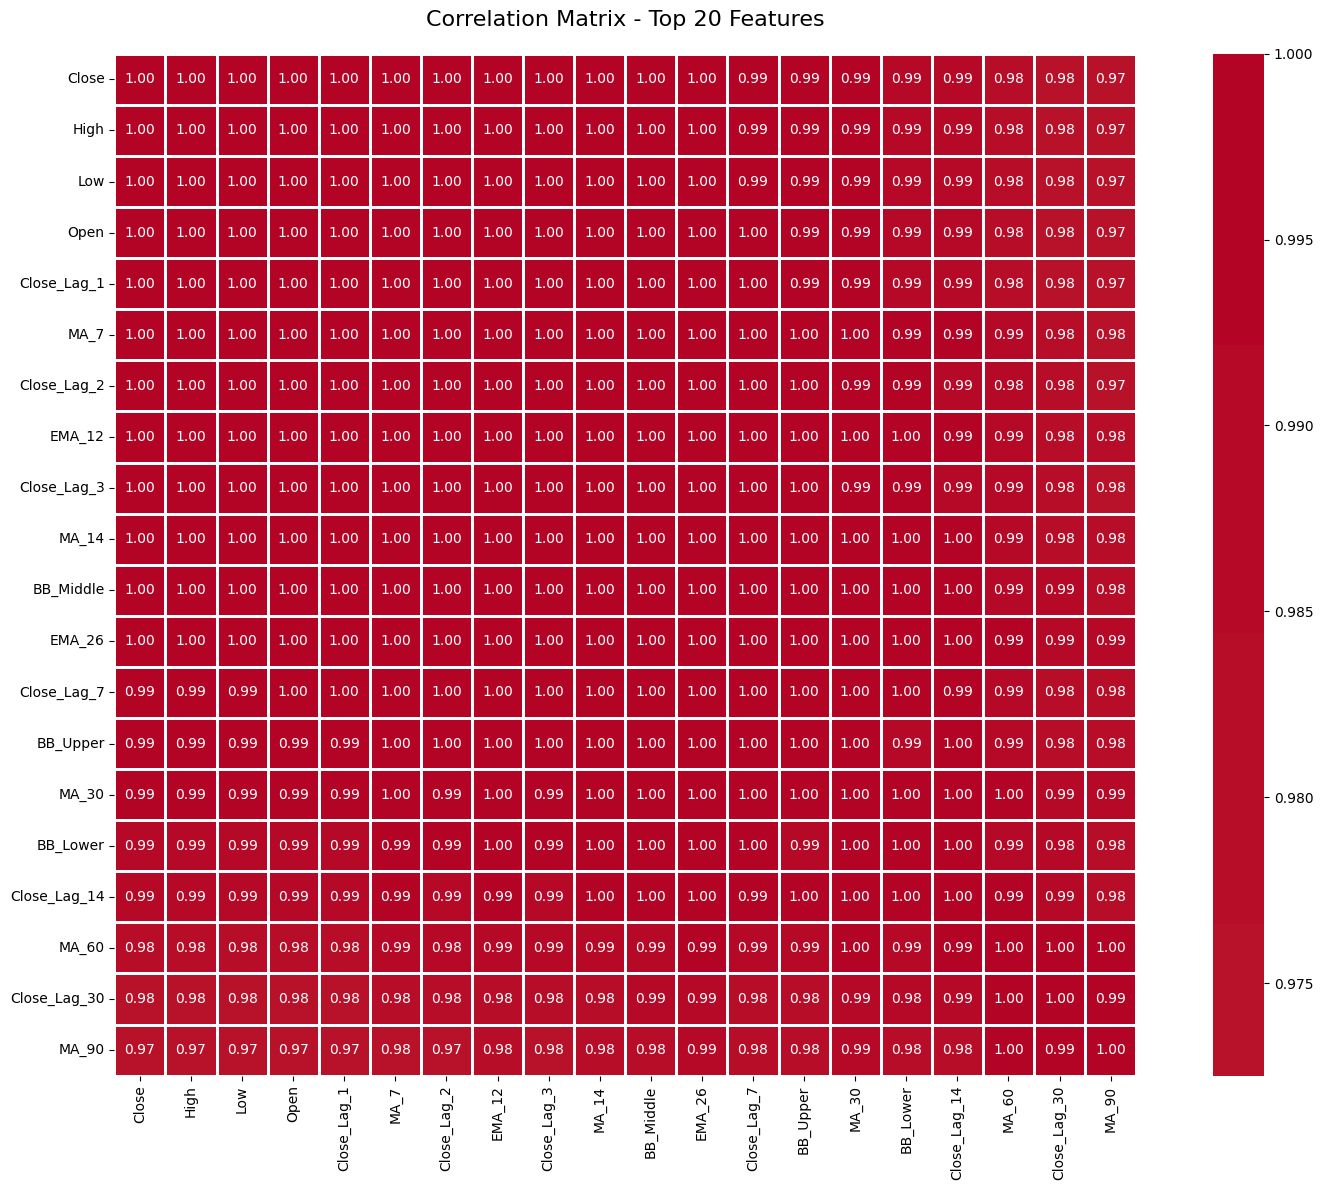

In [7]:
# CORRELATION ANALYSIS

print("\n" + "="*80)
print("CORRELATION ANALYSIS")
print("="*80)

# Drop NaN values for correlation analysis
df_clean = df.dropna()
print(f"\n📊 Clean dataset shape: {df_clean.shape}")

# Calculate correlations with Close price
correlations = df_clean.corr()['Close'].sort_values(ascending=False)
print("\n🔝 Top 15 Features Correlated with Close Price:")
print(correlations.head(15))

print("\n🔻 Bottom 10 Features Correlated with Close Price:")
print(correlations.tail(10))

# Visualize correlation matrix (top features only)
plt.figure(figsize=(16, 12))
top_features = correlations.head(20).index
corr_matrix = df_clean[top_features].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1)
plt.title('Correlation Matrix - Top 20 Features', fontsize=16, pad=20)
plt.tight_layout()
plt.show()



FEATURE SELECTION

🔍 Removing highly correlated features (>0.95)...
Features to drop: ['High', 'Low', 'Taker buy base asset volume', 'Taker buy quote asset volume', 'MA_7', 'MA_14', 'Volume_MA_14', 'MA_30', 'Volume_MA_30', 'MA_60', 'Volume_MA_60', 'MA_90', 'Volume_MA_90', 'EMA_12', 'EMA_26', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'BB_Width', 'Close_Lag_1', 'Close_Lag_2', 'Close_Lag_3', 'Close_Lag_7', 'Close_Lag_14', 'Close_Lag_30', 'Return_1d', 'Quote_Volume_Ratio', 'Quarter', 'Week_of_Year', 'High_Low_Range_14', 'High_Low_Range_30']
✓ Remaining features: 38

🎯 Calculating feature importance using Random Forest...

Training set: (2261, 37)
Test set: (566, 37)

🏆 Top 20 Most Important Features:
               feature  importance
0                 Open    0.996993
5         Price_Change    0.000744
23  Volume_Price_Trend    0.000683
6     Price_Change_Pct    0.000634
11         BB_Position    0.000109
4          Price_Range    0.000077
22     Taker_Buy_Ratio    0.000074
8  

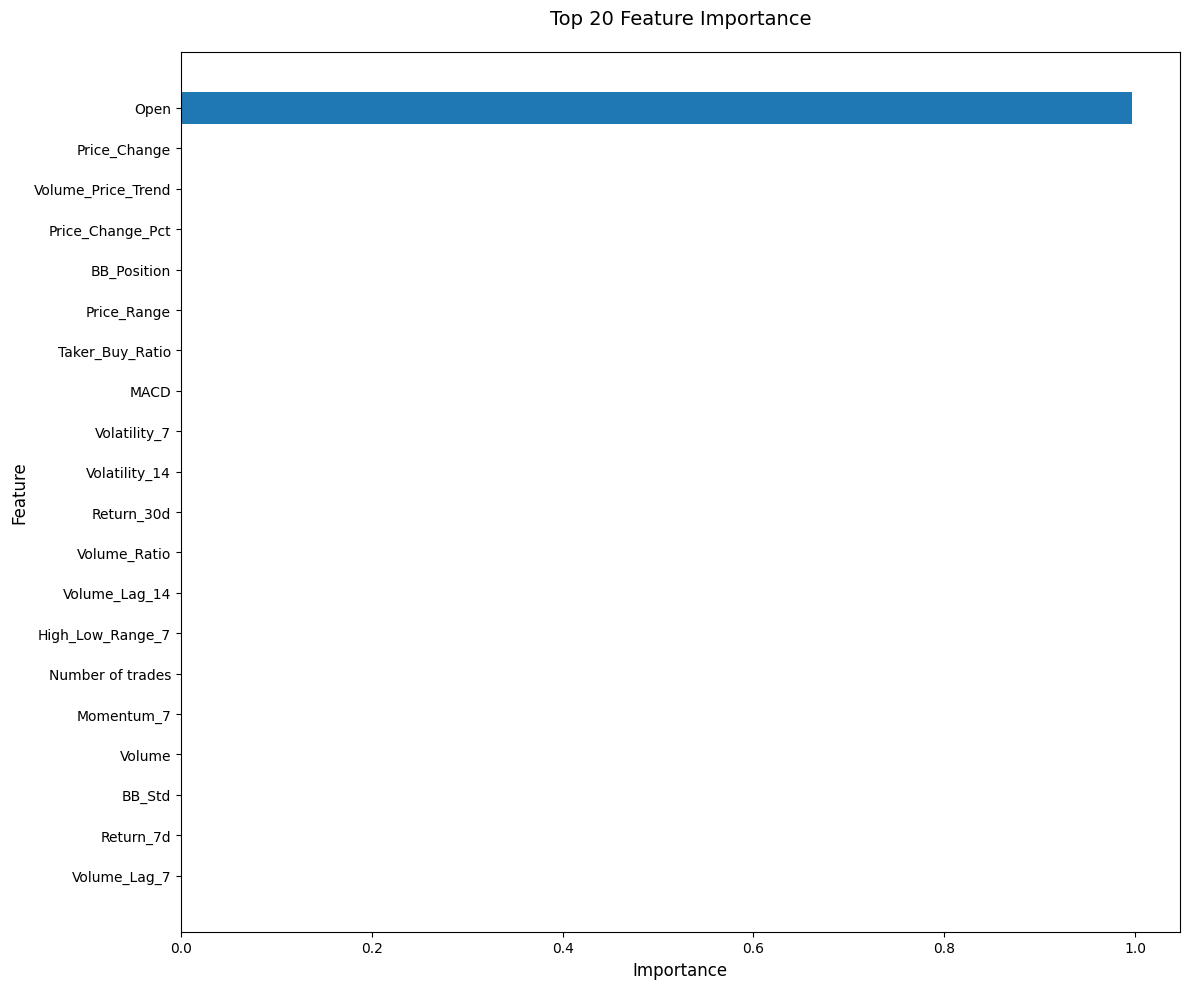


📊 Applying Variance Threshold...
✓ Features after variance threshold: 35


In [8]:
# FEATURE SELECTION

print("\n" + "="*80)
print("FEATURE SELECTION")
print("="*80)

# Remove highly correlated features (threshold > 0.95)
print("\n🔍 Removing highly correlated features (>0.95)...")
correlation_matrix = df_clean.corr().abs()
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Find highly correlated features but NEVER drop the target variable
to_drop = [column for column in upper_triangle.columns 
           if any(upper_triangle[column] > 0.95) and column != 'Close']
print(f"Features to drop: {to_drop}")
df_clean = df_clean.drop(columns=to_drop)
print(f"✓ Remaining features: {len(df_clean.columns)}")

# Prepare data for feature importance
print("\n🎯 Calculating feature importance using Random Forest...")
X = df_clean.drop(columns=['Close'])
y = df_clean['Close']

# Split data (time series split - no shuffle)
split_index = int(len(X) * 0.8)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"\nTraining set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

# Train Random Forest for feature importance
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Get feature importance
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\n🏆 Top 20 Most Important Features:")
print(feature_importance.head(20))

# Visualize feature importance
plt.figure(figsize=(12, 10))
plt.barh(feature_importance.head(20)['feature'], 
         feature_importance.head(20)['importance'])
plt.xlabel('Importance', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.title('Top 20 Feature Importance', fontsize=14, pad=20)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Variance Threshold
print("\n📊 Applying Variance Threshold...")
selector = VarianceThreshold(threshold=0.01)
X_high_variance = selector.fit_transform(X)
selected_features = X.columns[selector.get_support()].tolist()
print(f"✓ Features after variance threshold: {len(selected_features)}")



DISTRIBUTION ANALYSIS


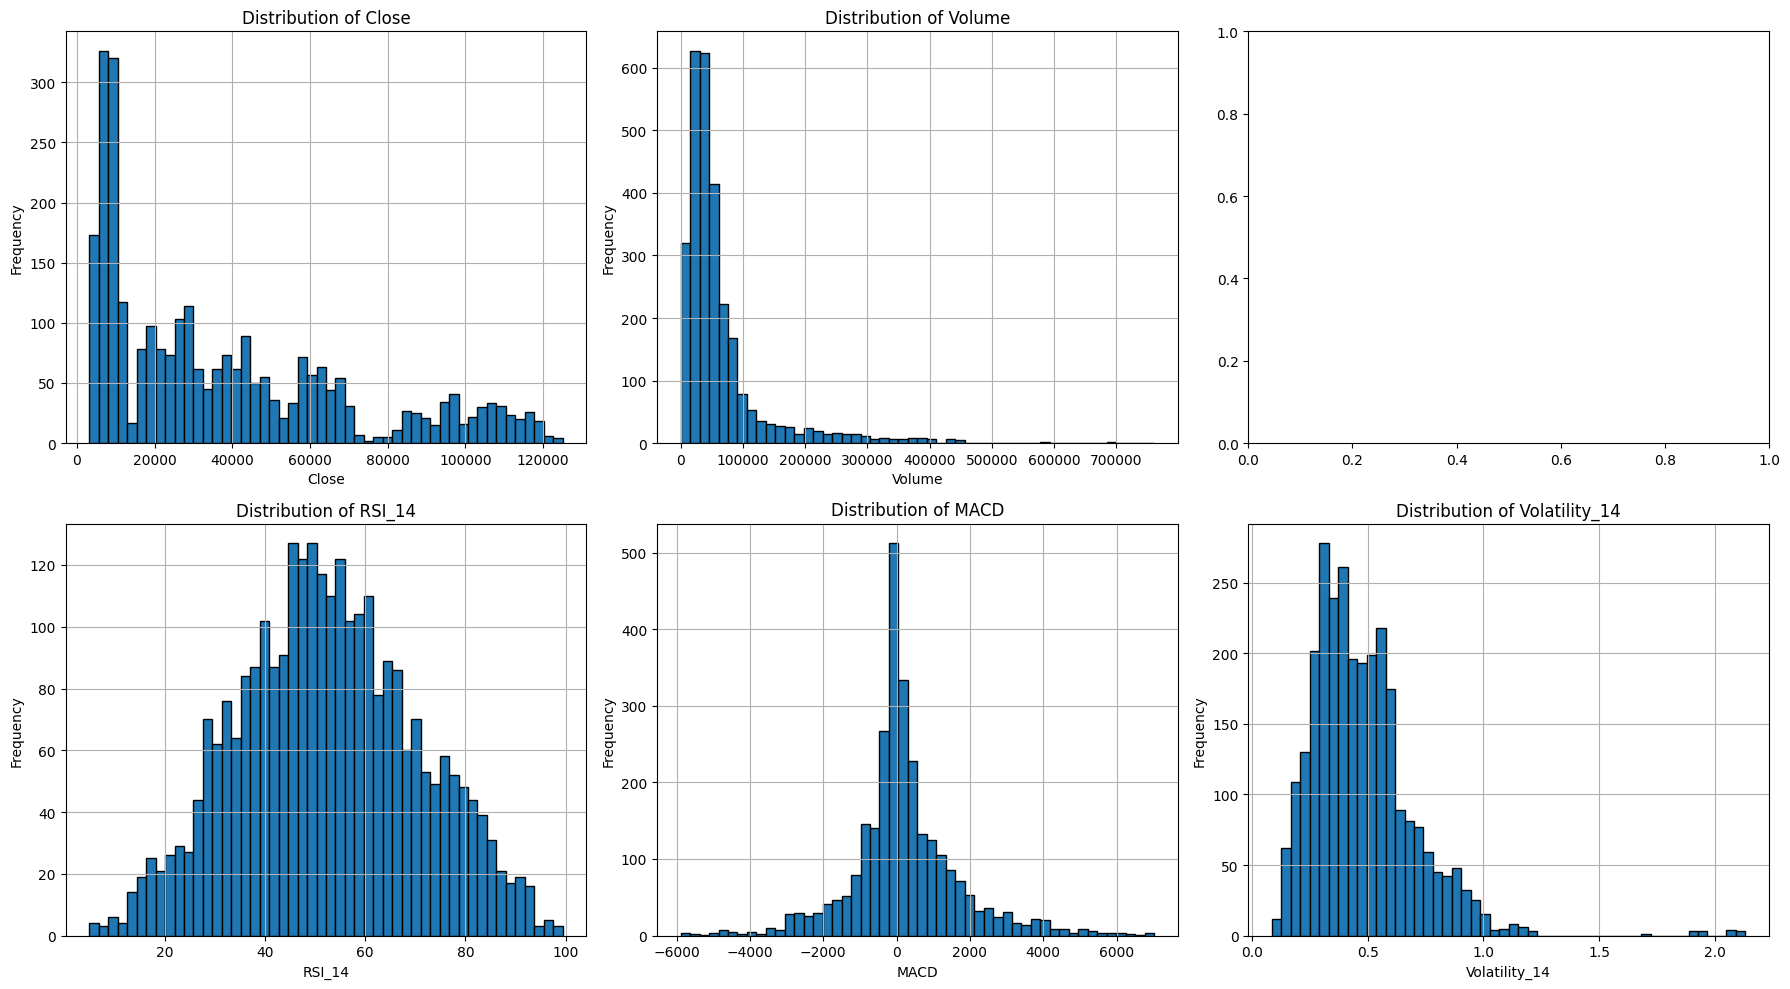

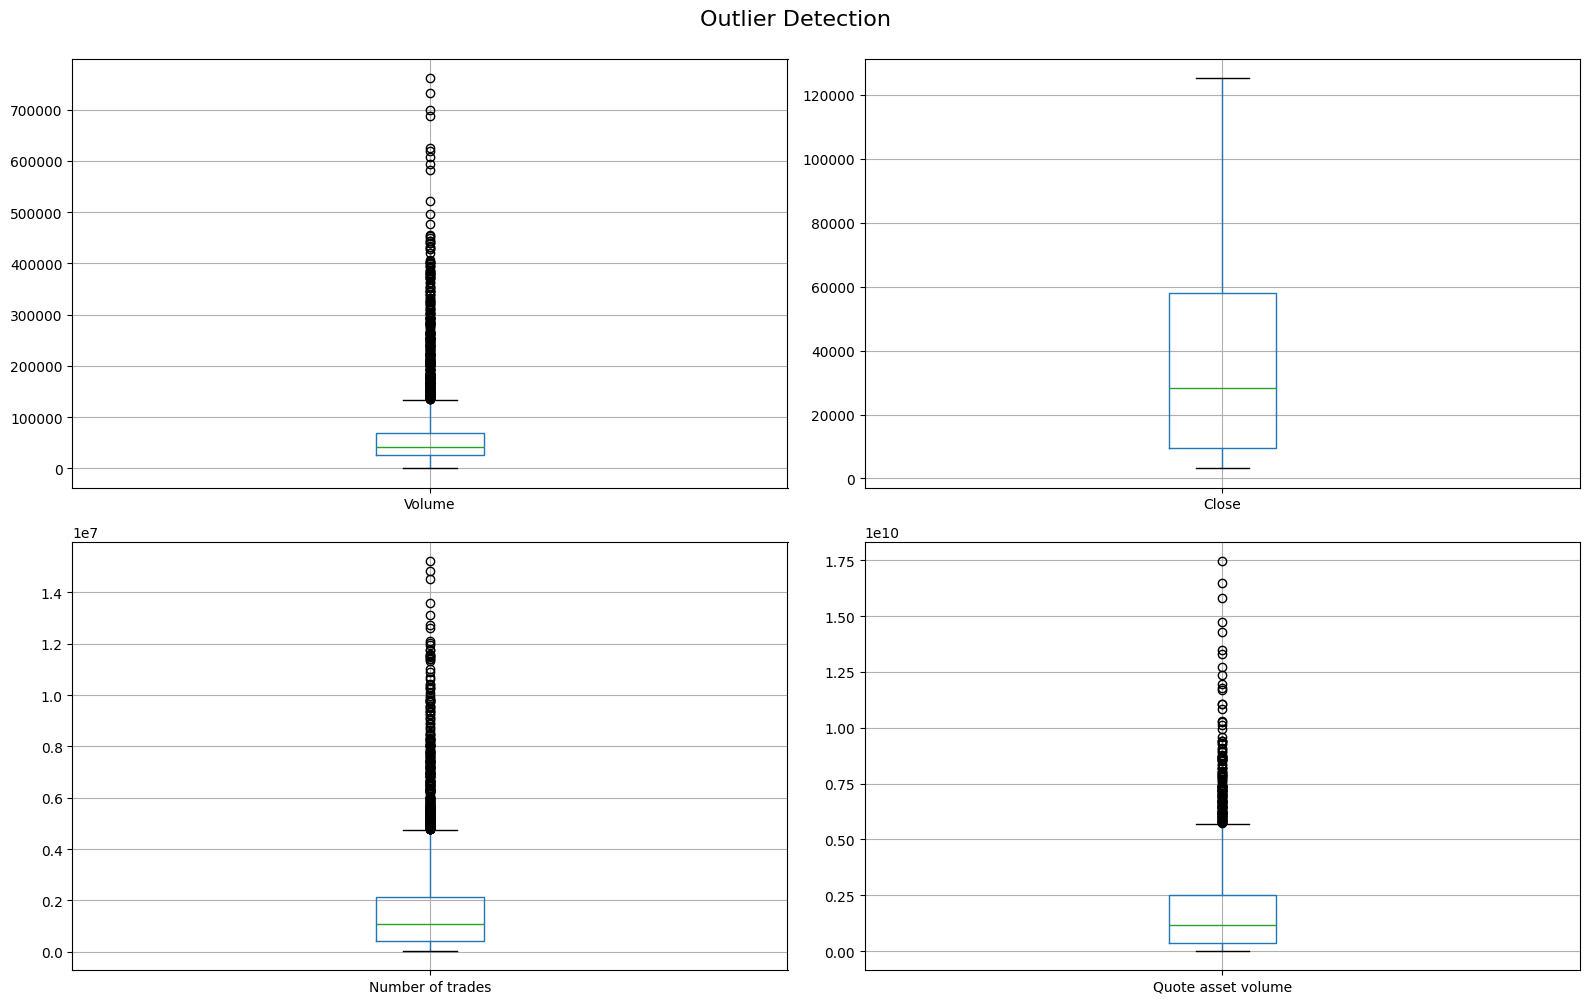

In [9]:
# DISTRIBUTION ANALYSIS

print("\n" + "="*80)
print("DISTRIBUTION ANALYSIS")
print("="*80)

# Create distribution plots for key features
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
features_to_plot = ['Close', 'Volume', 'Return_1d', 'RSI_14', 'MACD', 'Volatility_14']

for idx, feature in enumerate(features_to_plot):
    row = idx // 3
    col = idx % 3
    if feature in df_clean.columns:
        df_clean[feature].hist(bins=50, ax=axes[row, col], edgecolor='black')
        axes[row, col].set_title(f'Distribution of {feature}', fontsize=12)
        axes[row, col].set_xlabel(feature)
        axes[row, col].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Box plots for outlier detection
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
df_clean.boxplot(column='Volume', ax=axes[0,0])
df_clean.boxplot(column='Close', ax=axes[0,1])
df_clean.boxplot(column='Number of trades', ax=axes[1,0])
df_clean.boxplot(column='Quote asset volume', ax=axes[1,1])
plt.suptitle('Outlier Detection', fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

In [10]:
print("\n📈 Creating technical indicator visualizations...")

# Use original df with all features for technical visualization
df_viz = df.dropna()

# Create subplots for technical analysis
fig = make_subplots(
    rows=4, cols=1,
    shared_xaxes=True,
    subplot_titles=('Price with Moving Averages', 'Bollinger Bands', 'RSI', 'MACD'),
    vertical_spacing=0.05,
    row_heights=[0.4, 0.2, 0.2, 0.2]
)

# Price with MAs
fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['Close'], 
                         name='Close', line=dict(color='white')), row=1, col=1)
if 'MA_7' in df_viz.columns:
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['MA_7'], 
                             name='MA 7', line=dict(color='cyan')), row=1, col=1)
if 'MA_30' in df_viz.columns:
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['MA_30'], 
                             name='MA 30', line=dict(color='yellow')), row=1, col=1)

# Bollinger Bands
if all(col in df_viz.columns for col in ['BB_Upper', 'BB_Middle', 'BB_Lower']):
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['BB_Upper'], 
                             name='BB Upper', line=dict(color='red', dash='dash')), row=2, col=1)
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['BB_Middle'], 
                             name='BB Middle', line=dict(color='white')), row=2, col=1)
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['BB_Lower'], 
                             name='BB Lower', line=dict(color='green', dash='dash')), row=2, col=1)

# RSI
if 'RSI_14' in df_viz.columns:
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['RSI_14'], 
                             name='RSI', line=dict(color='purple')), row=3, col=1)
    fig.add_hline(y=70, line_dash="dash", line_color="red", row=3, col=1)
    fig.add_hline(y=30, line_dash="dash", line_color="green", row=3, col=1)

# MACD
if all(col in df_viz.columns for col in ['MACD', 'MACD_Signal']):
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['MACD'], 
                             name='MACD', line=dict(color='blue')), row=4, col=1)
    fig.add_trace(go.Scatter(x=df_viz.index, y=df_viz['MACD_Signal'], 
                             name='Signal', line=dict(color='orange')), row=4, col=1)

fig.update_layout(
    height=1000,
    width=1400,
    title_text="Technical Indicators Analysis",
    template="plotly_dark",
    showlegend=True
)

fig.show()


📈 Creating technical indicator visualizations...


In [11]:
# SUMMARY AND RECOMMENDATIONS

print("\n" + "="*80)
print("SUMMARY & RECOMMENDATIONS")
print("="*80)

print(f"""
📋 DATASET SUMMARY:
- Total records: {len(df_clean)}
- Date range: {df_clean.index.min().date()} to {df_clean.index.max().date()}
- Total features: {len(df_clean.columns)}
- Training samples: {len(X_train)}
- Test samples: {len(X_test)}

🎯 KEY FINDINGS:
1. Price shows clear trends with periods of high volatility
2. Volume and price are moderately correlated
3. Technical indicators (MA, RSI, MACD) show meaningful patterns
4. Strong autocorrelation in price data suggests lag features are valuable


💡 TOP FEATURES TO USE:
{feature_importance.head(10)['feature'].tolist()}

""")

print("\n✅ Analysis complete! Data is ready for modeling.")

# Save cleaned dataset
output_path = 'btc_engineered_features.csv'
df_clean.to_csv(output_path)
print(f"\n💾 Engineered features saved to: {output_path}")


SUMMARY & RECOMMENDATIONS

📋 DATASET SUMMARY:
- Total records: 2827
- Date range: 2018-03-31 to 2025-12-25
- Total features: 38
- Training samples: 2261
- Test samples: 566

🎯 KEY FINDINGS:
1. Price shows clear trends with periods of high volatility
2. Volume and price are moderately correlated
3. Technical indicators (MA, RSI, MACD) show meaningful patterns
4. Strong autocorrelation in price data suggests lag features are valuable


💡 TOP FEATURES TO USE:
['Open', 'Price_Change', 'Volume_Price_Trend', 'Price_Change_Pct', 'BB_Position', 'Price_Range', 'Taker_Buy_Ratio', 'MACD', 'Volatility_7', 'Volatility_14']



✅ Analysis complete! Data is ready for modeling.

💾 Engineered features saved to: btc_engineered_features.csv
